# Déficit o superávit de las administraciones públicas

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"  # carpeta en research/temas/
GRAFICA_ID = "deficit-publico"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Déficit o superávit de las administraciones públicas"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB (negativo: déficit; positivo: superávit)"  # capacidad (+) o necesidad (−) de financiación
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = 0  # línea horizontal en el 0: separa el déficit (debajo) del superávit (encima)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** La diferencia entre los ingresos y los gastos del conjunto de las administraciones públicas en un año, en porcentaje del PIB. En España incluye el Estado, las comunidades autónomas, las entidades locales y la Seguridad Social; en los demás países, sus equivalentes. En contabilidad nacional se llama *capacidad (+) o necesidad (−) de financiación* (partida B.9).

**Cómo se lee.** Un valor de −3 significa un déficit equivalente al 3 % del PIB: ese año las administraciones gastaron más de lo que ingresaron y financiaron la diferencia, normalmente con deuda. Un valor positivo es un superávit. La línea en el 0 separa el déficit (debajo) del superávit (encima). Las reglas fiscales europeas toman como referencia un déficit del 3 % del PIB, medido con la cifra que cada país notifica a Eurostat en el *procedimiento de déficit excesivo*; la sección 3 comprueba que, para España, coincide con la serie de esta gráfica.

**Limitaciones.**
- Es el saldo total: incluye operaciones puntuales que no se repiten (p. ej. las ayudas a entidades financieras de 2012 en España) y depende del ciclo económico, porque en las recesiones bajan los ingresos y suben algunos gastos aunque no cambie la política fiscal. No es el saldo estructural.
- Abarca todas las administraciones, así que no coincide con el saldo del presupuesto del Estado o del gobierno federal que se suele citar en cada país.
- Los datos de España anteriores a 1995 y los de Canadá anteriores a 1981 no siguen la metodología contable vigente: la OCDE los reconstruye hacia atrás con otras fuentes (ver notas).
- Las medias de la OCDE y de la UE-27 son agregados ponderados por el tamaño de cada economía: pesan más los países grandes.
- Solo se muestran años con dato observado: se descartan las proyecciones que acompañan a cada edición del *Economic Outlook* de la OCDE.

## 2. Descarga

- **España, OCDE, EE. UU. y Canadá:** OCDE, *Economic Outlook* (`OECD.ECO.MAD,DSD_EO@DF_EO`), variable `NLGQ` (capacidad o necesidad de financiación de las administraciones públicas, % del PIB). La media de la OCDE es el área `OECD`.
- **Último año observado:** fichero *Last historical points* de la misma edición del *Economic Outlook*, enlazado en los metadatos del dataflow; sirve para descartar las proyecciones.
- **UE-27:** Eurostat `gov_10dd_edpt1` (sector `S13`, `B9`, `PC_GDP`), la cifra notificada en el procedimiento de déficit excesivo.

Solo para las comprobaciones y las notas de la sección 3 (no se publican como series): `NLGQ`, PIB nominal (`GDP`) y paridades de poder adquisitivo (`PPP`) de los 38 países miembros de la OCDE, para reconstruir la media; las operaciones puntuales netas estimadas por la OCDE (`NOOQ`, % del PIB potencial); el déficit de España en Eurostat (`gov_10dd_edpt1`, en % del PIB y en millones de euros junto con el PIB) y las transferencias de capital pagadas por las administraciones públicas de España (Eurostat `gov_10a_main`, `D9PAY`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

import io
import re
import xml.etree.ElementTree as ET

import requests

from lib import eurostat, oecd
from lib._http import pedir
from lib.tipos import FuenteMeta

# OCDE, Economic Outlook. Cada edición publica una versión nueva del dataflow y la versión fija la edición
# (datos y fichero de últimos datos observados); la sección 3 comprueba que sea la última publicada.
DATAFLOW = "OECD.ECO.MAD,DSD_EO@DF_EO,1.5"
# Clave: REF_AREA.MEASURE.FREQ · NLGQ: capacidad (+) o necesidad (−) de financiación de las AA. PP., % del PIB · A: anual
CLAVE = "{AREA}.NLGQ.A"
# OECD es la media de la OCDE en el Economic Outlook
AREAS = {"ESP": "espana", "OECD": "ocde", "USA": "eeuu", "CAN": "canada"}
# Los 38 países miembros de la OCDE, con su nombre para las notas
MIEMBROS_OCDE = {
    "AUS": "Australia", "AUT": "Austria", "BEL": "Bélgica", "CAN": "Canadá", "CHE": "Suiza", "CHL": "Chile",
    "COL": "Colombia", "CRI": "Costa Rica", "CZE": "Chequia", "DEU": "Alemania", "DNK": "Dinamarca",
    "ESP": "España", "EST": "Estonia", "FIN": "Finlandia", "FRA": "Francia", "GBR": "Reino Unido",
    "GRC": "Grecia", "HUN": "Hungría", "IRL": "Irlanda", "ISL": "Islandia", "ISR": "Israel", "ITA": "Italia",
    "JPN": "Japón", "KOR": "Corea del Sur", "LTU": "Lituania", "LUX": "Luxemburgo", "LVA": "Letonia",
    "MEX": "México", "NLD": "Países Bajos", "NOR": "Noruega", "NZL": "Nueva Zelanda", "POL": "Polonia",
    "PRT": "Portugal", "SVK": "Eslovaquia", "SVN": "Eslovenia", "SWE": "Suecia", "TUR": "Turquía",
    "USA": "Estados Unidos",
}


def pedir_oecd(url, etiqueta):
    """GET de metadatos o ficheros de la OCDE, con los reintentos de lib/_http."""
    return pedir(
        requests.Session(), url, None, error_cls=oecd.OecdError, etiqueta=etiqueta,
        mensaje=lambda r: r.text[:200],
    )


def metadatos_eo():
    """Última versión publicada del dataflow y URL del fichero «Last historical points» de la versión usada."""
    agencia, flujo, version = DATAFLOW.split(",")
    base = oecd.BASE.removesuffix("/data") + f"/dataflow/{agencia}/{flujo}"
    ns = {"s": "http://www.sdmx.org/resources/sdmxml/schemas/v2_1/structure"}
    ultima = ET.fromstring(pedir_oecd(f"{base}/latest", "versión").content).find(".//s:Dataflow", ns).get("version")
    texto = pedir_oecd(f"{base}/{version}", "metadatos").text
    urls = sorted(set(re.findall(r"https://[^\s\"'<>&]+Last_Historical[^\s\"'<>&]+\.xlsx", texto)))
    if len(urls) != 1:
        raise oecd.OecdError(f"se esperaba un enlace al fichero de últimos datos observados y hay {len(urls)}")
    return ultima, urls[0]


def ultimos_observados(url, variable="NLGQ"):
    """Último año observado (no proyectado) de `variable` por país, según el fichero «Last historical points»."""
    bruto = pd.read_excel(io.BytesIO(pedir_oecd(url, "últimos datos observados").content), header=None)
    fila = next(i for i, v in bruto.iloc[:, 0].items() if v == "Country Code")
    tabla = bruto.iloc[fila + 1:].set_axis(bruto.iloc[fila].tolist(), axis=1)
    tabla = tabla[tabla["Variable code"] == variable]
    return {
        c: int(a) for c, a in zip(tabla["Country Code"], tabla["Last Observation annual"]) if pd.notna(a)
    }


df_eo, fuentes_eo = oecd.get(DATAFLOW, CLAVE, areas=AREAS, desde=DESDE)
version_ultima, url_lho = metadatos_eo()
ultimo_obs = ultimos_observados(url_lho)
EDICION = re.search(r"EO_?(\d+)\.xlsx$", url_lho).group(1)

# Solo para comprobar la media de la OCDE: NLGQ, PIB nominal (moneda nacional) y PPA (moneda nacional por dólar)
miembros = {c: c for c in MIEMBROS_OCDE}
m_nlgq, _ = oecd.get(DATAFLOW, CLAVE, areas=miembros, desde=DESDE)
m_pib, _ = oecd.get(DATAFLOW, "{AREA}.GDP.A", areas=miembros, desde=DESDE)
m_ppa, _ = oecd.get(DATAFLOW, "{AREA}.PPP.A", areas=miembros, desde=DESDE)
# Operaciones puntuales netas de las AA. PP. estimadas por la OCDE (% del PIB potencial): notas y comprobaciones
puntuales, _ = oecd.get(DATAFLOW, "{AREA}.NOOQ.A", areas={"ESP": "espana", "USA": "eeuu", "CAN": "canada"}, desde=DESDE)

# Eurostat, procedimiento de déficit excesivo: UE-27 (serie publicada) y España (para comparar con la OCDE)
EDP = {"freq": "A", "unit": "PC_GDP", "sector": "S13", "na_item": "B9"}
edp, fuentes_edp = eurostat.get("gov_10dd_edpt1", EDP, geos={"EU27_2020": "ue27", "ES": "espana_edp"}, desde=DESDE)
edp_b9, _ = eurostat.get("gov_10dd_edpt1", {**EDP, "unit": "MIO_EUR"}, geos={"ES": "espana_edp"}, desde=DESDE)
edp_pib, _ = eurostat.get(
    "gov_10dd_edpt1", {"freq": "A", "unit": "MIO_EUR", "sector": "S1", "na_item": "B1GQ"},
    geos={"ES": "espana_edp"}, desde=DESDE,
)
# Transferencias de capital pagadas por las AA. PP. de España (D9PAY), % del PIB: para la nota de 2012
d9, _ = eurostat.get(
    "gov_10a_main", {"freq": "A", "unit": "PC_GDP", "sector": "S13", "na_item": "D9PAY"},
    geos={"ES": "espana"}, desde=DESDE,
)
print(f"Economic Outlook {EDICION} (dataflow versión {DATAFLOW.rsplit(',', 1)[1]})")

Economic Outlook 119 (dataflow versión 1.5)


## 3. Transformación

La OCDE y Eurostat ya publican el saldo en porcentaje del PIB: no hay deflactor, cambio de unidades ni enlace de series propio. Solo se descartan las proyecciones del *Economic Outlook*:

- **España, EE. UU. y Canadá:** cada serie llega hasta el último año observado de `NLGQ` que da para ese país el fichero *Last historical points* de la misma edición.
- **Media de la OCDE:** ese fichero no da fecha para los agregados. Se corta en el último año en que **todos** los países que la componen tienen dato observado (el mínimo de sus últimos años observados); en los años siguientes la media mezcla datos observados y proyecciones de la OCDE.

In [ ]:
# Países que entran en la media de la OCDE: los miembros con NLGQ en el Economic Outlook
miembros_media = sorted(m_nlgq["serie"].unique())
sin_fecha = [c for c in [*miembros_media, "ESP", "USA", "CAN"] if c not in ultimo_obs]
if sin_fecha:
    raise ValueError(f"sin último año observado en el fichero de la OCDE: {', '.join(sin_fecha)}")

ULTIMO = {AREAS[c]: ultimo_obs[c] for c in ("ESP", "USA", "CAN")}
ULTIMO["ocde"] = min(ultimo_obs[c] for c in miembros_media)
proyectado = df_eo["periodo"] > df_eo["serie"].map(ULTIMO)
print("Último año observado:", ULTIMO)
print("Años descartados (proyecciones):", {
    s: f"{g.min()}-{g.max()}" for s, g in df_eo[proyectado].groupby("serie")["periodo"]
})
eo = df_eo[~proyectado]

ue27 = edp[edp["serie"] == "ue27"]
df = pd.concat([eo, ue27], ignore_index=True)

CODIGO_EO = f"{DATAFLOW} (Economic Outlook {EDICION}; NLGQ, sin proyecciones)"
fuentes = [FuenteMeta(f.serie, f.organismo, CODIGO_EO, f.url, f.fecha_consulta) for f in fuentes_eo]
fuentes += [
    FuenteMeta(f.serie, f.organismo, "gov_10dd_edpt1 (S13, B9, PC_GDP)", f.url, f.fecha_consulta)
    for f in fuentes_edp if f.serie == "ue27"
]
assert df["valor"].between(-30, 30).all(), "saldo fuera de rango: ¿unidades?"
df.pivot(index="periodo", columns="serie", values="valor").round(2).tail(12)

Último año observado: {'espana': 2025, 'eeuu': 2025, 'canada': 2025, 'ocde': 2023}
Años descartados (proyecciones): {'canada': '2026-2027', 'eeuu': '2026-2027', 'espana': '2026-2027', 'ocde': '2024-2027'}


serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2014,0.17,-5.28,-6.04,-3.53,-2.4
2015,-0.06,-4.67,-5.27,-2.88,-1.9
2016,-0.45,-5.43,-4.22,-2.93,-1.4
2017,-0.11,-4.45,-3.07,-2.33,-0.9
2018,0.36,-6.15,-2.55,-2.64,-0.4
2019,-0.02,-6.69,-3.06,-3.08,-0.5
2020,-10.95,-14.98,-9.91,-10.15,-6.7
2021,-3.06,-11.91,-6.65,-7.03,-4.6
2022,0.62,-3.69,-4.59,-2.93,-3.2


### Comprobaciones

No cambian los datos publicados:
1. Que la versión fijada del dataflow sea la última que publica la OCDE.
2. España: la serie de la OCDE frente a la cifra notificada a Eurostat en el procedimiento de déficit excesivo, la publicada (un decimal) y la recalculada con los importes en millones de euros (déficit entre PIB).
3. Media de la OCDE: se reconstruye como media de los países miembros con dato ponderada por su PIB en dólares PPA (PIB nominal entre PPA), se compara con la publicada y se cuentan los países que la componen cada año. También, el peso de los países con proyecciones en los años posteriores al corte.
4. Años con operaciones puntuales grandes según la OCDE (`NOOQ`, al menos 1 punto del PIB potencial en valor absoluto) y transferencias de capital pagadas por las AA. PP. de España (Eurostat `D9PAY`).

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales)


# 1) Versión del dataflow
version = DATAFLOW.rsplit(",", 1)[1]
if version_ultima != version:
    print(f"AVISO: la OCDE publica la versión {version_ultima} del dataflow y aquí se usa la {version}: actualiza DATAFLOW.")
else:
    print(f"La versión usada del dataflow ({version}) es la última publicada por la OCDE.")

# 2) España: OCDE frente a Eurostat (procedimiento de déficit excesivo)
serie = lambda d, s="espana_edp": d[d["serie"] == s].set_index("periodo")["valor"]
comp = pd.DataFrame({
    "OCDE": serie(eo, "espana"),
    "Eurostat publicado": serie(edp),
    "Eurostat recalculado": serie(edp_b9) / serie(edp_pib) * 100,
}).dropna()
comp["dif. publicado"] = comp["OCDE"] - comp["Eurostat publicado"]
comp["dif. recalculado"] = comp["OCDE"] - comp["Eurostat recalculado"]
COMUN = (int(comp.index.min()), int(comp.index.max()))
DIF_PUB = comp["dif. publicado"].abs().max()
DIF_CALC = comp["dif. recalculado"].abs().max()
print(f"\nEspaña {COMUN[0]}-{COMUN[1]}: diferencia máxima OCDE − Eurostat {DIF_PUB:.3f} (publicado), {DIF_CALC:.4f} (recalculado)")
display(comp.loc[2007:].round(3))

# 3) Media de la OCDE
w = pd.concat([m_nlgq.assign(m="NLGQ"), m_pib.assign(m="PIB"), m_ppa.assign(m="PPA")])
w = w.pivot_table(index=["serie", "periodo"], columns="m", values="valor").dropna(subset=["NLGQ"])
w["peso"] = w["PIB"] / w["PPA"]  # PIB en dólares PPA
media = w.groupby("periodo").apply(lambda g: (g["NLGQ"] * g["peso"]).sum() / g["peso"].sum())
paises = w.reset_index().groupby("periodo")["serie"].apply(set)
rec = pd.DataFrame({"países": paises.map(len), "reconstruida": media, "publicada": serie(df_eo, "ocde")})
rec = rec.dropna(subset=["publicada"]).loc[: ULTIMO["ocde"]]
rec["dif."] = rec["reconstruida"] - rec["publicada"]
distinta = rec.index[rec["dif."].abs() >= 0.01]
COINCIDE_DESDE = int(distinta.max()) + 1 if len(distinta) else int(rec.index.min())
SIN_SERIE = sorted(MIEMBROS_OCDE[c] for c in MIEMBROS_OCDE if c not in miembros_media)
A0, N0, N_MEDIA = int(rec.index.min()), int(rec["países"].iloc[0]), len(miembros_media)
A_COMPLETA = int(rec.index[rec["países"] == N_MEDIA].min())
print(f"\nMedia OCDE: {N_MEDIA} miembros con NLGQ (sin {', '.join(SIN_SERIE)}).")
print(f"Coincide con la media ponderada por el PIB en PPA (|dif.| < 0,01) desde {COINCIDE_DESDE}.")
cambios = rec[rec["países"].diff().fillna(1) != 0]
for a in cambios.index:
    nuevos = paises[a] - paises.get(a - 1, set()) if a > A0 else set()
    print(f"  {a}: {rec.loc[a, 'países']} países" + (f" (entran {', '.join(sorted(nuevos))})" if nuevos else ""))
display(rec.round(3).iloc[::5])

fin = max(ULTIMO.values())
PROYECTADOS = sorted(MIEMBROS_OCDE[c] for c in miembros_media if ultimo_obs[c] < fin)
for a in range(ULTIMO["ocde"] + 1, fin + 1):
    g = w.xs(a, level="periodo")
    proy = [c for c in g.index if ultimo_obs[c] < a]
    print(f"{a}: con proyección {', '.join(MIEMBROS_OCDE[c] for c in proy)}: "
          f"{fmt(g.loc[proy, 'peso'].sum() / g['peso'].sum() * 100)} % del PIB en PPA de la media")

# 4) Operaciones puntuales (OCDE, NOOQ) y transferencias de capital de España (Eurostat, D9PAY)
grandes = puntuales[(puntuales["valor"].abs() >= 1) & (puntuales["periodo"] <= puntuales["serie"].map(ULTIMO))]
print("\nOperaciones puntuales netas de al menos 1 punto del PIB potencial (OCDE, NOOQ):")
display(grandes.round(2))
NOO_2012 = serie(puntuales, "espana")[2012]
D9 = serie(d9, "espana")
assert NOO_2012 < 0 and D9[2012] > D9[2011], "se esperaba un aumento del déficit por operaciones puntuales en 2012"
print("España, transferencias de capital pagadas (% del PIB):", ", ".join(f"{a} {fmt(D9[a])}" for a in range(2010, 2015)))

La versión usada del dataflow (1.5) es la última publicada por la OCDE.

España 1995-2025: diferencia máxima OCDE − Eurostat 0.049 (publicado), 0.0000 (recalculado)


,OCDE,Eurostat publicado,Eurostat recalculado,dif. publicado,dif. recalculado
periodo,,,,,
2007,1.883,1.9,1.883,-0.017,-0.0
2008,-4.560,-4.6,-4.560,0.040,-0.0
2009,-11.237,-11.2,-11.237,-0.037,-0.0
2010,-9.487,-9.5,-9.487,0.013,-0.0
2011,-9.692,-9.7,-9.692,0.008,-0.0
2012,-11.496,-11.5,-11.496,0.004,-0.0
2013,-7.488,-7.5,-7.488,0.012,0.0
2014,-6.036,-6.0,-6.036,-0.036,0.0
2015,-5.266,-5.3,-5.266,0.034,-0.0



Media OCDE: 34 miembros con NLGQ (sin Chile, Colombia, Costa Rica, México).
Coincide con la media ponderada por el PIB en PPA (|dif.| < 0,01) desde 1998.
  1991: 23 países
  1995: 32 países (entran CZE, EST, GRC, HUN, LTU, LVA, POL, SVK, SVN)
  1998: 33 países (entran ISR)
  2009: 34 países (entran TUR)


,países,reconstruida,publicada,dif.
periodo,,,,
1991,23,-4.151,-4.201,0.050
1996,32,-3.751,-3.786,0.035
2001,33,-2.036,-2.036,-0.000
2006,33,-1.996,-1.996,-0.000
2011,34,-6.745,-6.745,-0.000
2016,34,-2.928,-2.928,0.000
2021,34,-7.029,-7.029,-0.000


2024: con proyección Nueva Zelanda: 0,4 % del PIB en PPA de la media
2025: con proyección Suiza, Israel, Japón, Corea del Sur, Nueva Zelanda, Turquía: 19,1 % del PIB en PPA de la media

Operaciones puntuales netas de al menos 1 punto del PIB potencial (OCDE, NOOQ):


,serie,periodo,valor
70,eeuu,2017,1.27
89,espana,1993,-1.23
108,espana,2012,-3.33
116,espana,2020,1.18


España, transferencias de capital pagadas (% del PIB): 2010 0,9, 2011 1,3, 2012 4,4, 2013 1,3, 2014 1,0


### Notas

Una frase por decisión. Las cifras de las notas salen de las comprobaciones anteriores.

In [ ]:
def unir(nombres):
    nombres = list(nombres)
    return nombres[0] if len(nombres) == 1 else f"{', '.join(nombres[:-1])} y {nombres[-1]}"


# Rupturas: primer año con datos del sistema contable vigente en las cuentas no financieras de las AA. PP.
# (documentación de la base de datos del Economic Outlook, anexo A3.2, «Coverage and reporting systems»: «Time
# series are backcasted in the EO database using data from other sources»). Misma nota en gasto, déficit e intereses.
RUPTURAS = (
    "Rupturas de serie en 1995 en España y en 1981 en Canadá: el Economic Outlook da las cuentas de las "
    "administraciones públicas con la metodología vigente (SEC 2010 y SCN 2008) desde esos años, y los anteriores "
    "son retropolaciones de la OCDE con otras fuentes (documentación de la base de datos, anexo A3.2). En EE. UU., "
    "las cuentas NIPA vigentes cubren todo el periodo."
)

por_anio = {}
for s, nombre in [("espana", "España"), ("eeuu", "EE. UU."), ("canada", "Canadá")]:
    por_anio.setdefault(ULTIMO[s], []).append(nombre)
ultimos = "; ".join(f"{a} en {unir(n)}" for a, n in por_anio.items())

if DIF_CALC < 0.01:
    contraste = (
        f"coincide con la notificada a Eurostat en el procedimiento de déficit excesivo (gov_10dd_edpt1), que es la "
        f"que se usa en las reglas fiscales europeas: las diferencias son menores de 0,01 puntos al calcular esta con "
        f"los importes en millones de euros, y de hasta {fmt(DIF_PUB, 2)} con la cifra que publica Eurostat, "
        f"redondeada a un decimal."
    )
else:
    contraste = (
        f"difiere hasta en {fmt(DIF_CALC, 2)} puntos de la notificada a Eurostat en el procedimiento de déficit "
        f"excesivo (gov_10dd_edpt1), que es la que se usa en las reglas fiscales europeas."
    )

# Otros años con operaciones puntuales de al menos 1 punto del PIB potencial según la OCDE (NOOQ), además de 2012
# en España: NOO es el efecto de esas operaciones en el saldo (saldo subyacente = saldo ajustado del ciclo − NOO,
# documentación de la base de datos, anexo 4), así que el signo positivo indica que lo mejoraron.
NOMBRES = {"espana": "España", "eeuu": "EE. UU.", "canada": "Canadá"}
otras = grandes[~((grandes["serie"] == "espana") & (grandes["periodo"] == 2012))].sort_values(["periodo", "serie"])
signo = lambda v: f"+{fmt(v)}" if v > 0 else f"−{fmt(abs(v))}"
inicio_noo = {}
for s, a in puntuales.groupby("serie")["periodo"].min().items():
    inicio_noo.setdefault(int(a), []).append(NOMBRES[s])
otras_puntuales = (
    "Otras operaciones puntuales: la OCDE estima que, además de las de 2012 en España, las operaciones puntuales "
    "netas movieron el saldo al menos 1 punto del PIB potencial en "
    + unir(f"{a} en {NOMBRES[s]} ({signo(v)})" for s, a, v in otras[["serie", "periodo", "valor"]].itertuples(index=False))
    + " (Economic Outlook, NOOQ; el signo positivo indica que mejoraron el saldo y el negativo, que lo empeoraron). "
    + "La OCDE da esta estimación " + unir(f"desde {a} en {unir(n)}" for a, n in sorted(inicio_noo.items())) + "."
) if len(otras) else None

NOTAS = [
    f"España, OCDE, EE. UU. y Canadá: OCDE, Economic Outlook n.º {EDICION} ({DATAFLOW.split(',')[1]}, versión "
    f"{DATAFLOW.rsplit(',', 1)[1]}), variable NLGQ, capacidad (+) o necesidad (−) de financiación de las "
    f"administraciones públicas en % del PIB.",
    f"Se descartan las proyecciones del Economic Outlook: cada país llega hasta su último año observado según el "
    f"fichero «Last historical points» de la misma edición ({ultimos}).",
    f"Media OCDE: agregado del Economic Outlook, ponderado por el PIB, de los países miembros con dato, {N_MEDIA} de "
    f"{len(MIEMBROS_OCDE)} (no incluye {unir(SIN_SERIE)}, sin esta serie en el Economic Outlook); su composición "
    f"cambia con los datos disponibles: {N0} países en {A0} y los {N_MEDIA} desde {A_COMPLETA}.",
    *(
        [f"La media de la OCDE llega hasta {ULTIMO['ocde']}, último año con dato observado en todos sus países; "
         f"en los años siguientes incluye proyecciones de la OCDE para {unir(PROYECTADOS)}."]
        if ULTIMO["ocde"] < fin else []
    ),
    "Media UE-27: Eurostat gov_10dd_edpt1 (sector S13, B9, % del PIB), la cifra notificada en el procedimiento de "
    "déficit excesivo, que Eurostat publica con un decimal; agregado de composición actual (EU27_2020).",
    f"España: de {COMUN[0]} a {COMUN[1]}, la serie de la OCDE {contraste}",
    RUPTURAS,
    f"2012: el déficit de España incluye las ayudas para recapitalizar entidades financieras, contabilizadas como "
    f"transferencias de capital: las que pagaron las administraciones públicas subieron al {fmt(D9[2012])} % del "
    f"PIB, desde el {fmt(D9[2011])} % de 2011 (Eurostat, gov_10a_main), y la OCDE estima que las operaciones "
    f"puntuales de ese año restaron {fmt(abs(NOO_2012))} puntos del PIB potencial al saldo (Economic Outlook, NOOQ).",
    *([otras_puntuales] if otras_puntuales else []),
]
for n in NOTAS:
    print("-", n)

- España, OCDE, EE. UU. y Canadá: OCDE, Economic Outlook n.º 119 (DSD_EO@DF_EO, versión 1.5), variable NLGQ, capacidad (+) o necesidad (−) de financiación de las administraciones públicas en % del PIB.
- Se descartan las proyecciones del Economic Outlook: cada país llega hasta su último año observado según el fichero «Last historical points» de la misma edición (2025 en España, EE. UU. y Canadá).
- Media OCDE: agregado del Economic Outlook, ponderado por el PIB, de los países miembros con dato, 34 de 38 (no incluye Chile, Colombia, Costa Rica y México, sin esta serie en el Economic Outlook); su composición cambia con los datos disponibles: 23 países en 1991 y los 34 desde 2009.
- La media de la OCDE llega hasta 2023, último año con dato observado en todos sus países; en los años siguientes incluye proyecciones de la OCDE para Corea del Sur, Israel, Japón, Nueva Zelanda, Suiza y Turquía.
- Media UE-27: Eurostat gov_10dd_edpt1 (sector S13, B9, % del PIB), la cifra notificada en el proced

## 4. Visualización

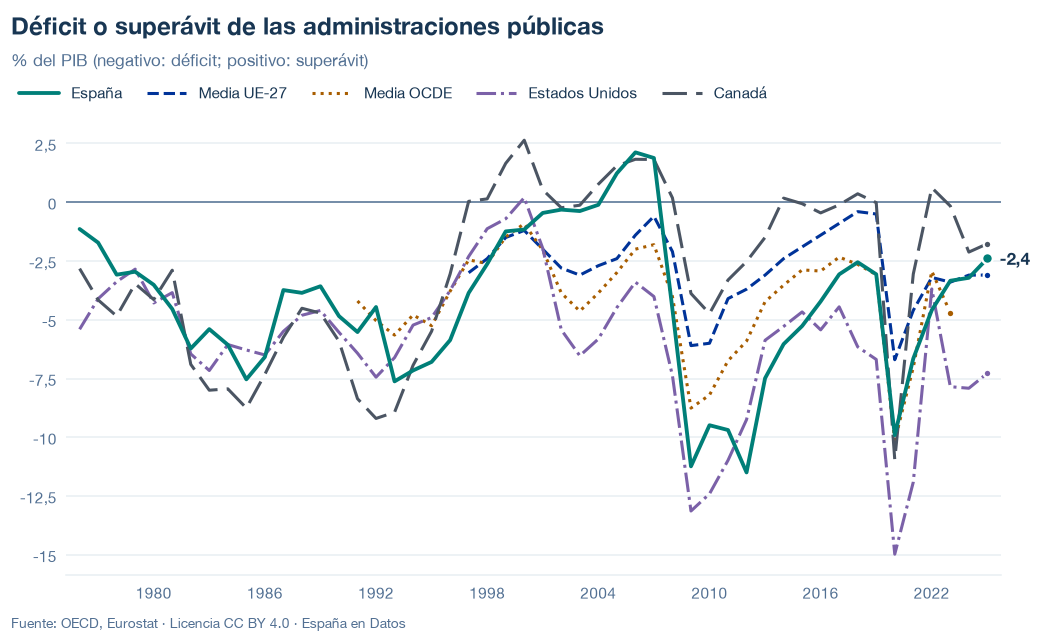

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/deficit-publico.json y data/deficit-publico.csv


## 6. Fuentes, notas y licencia

- OCDE, *Economic Outlook* (`OECD.ECO.MAD,DSD_EO@DF_EO`): `NLGQ` de España, EE. UU., Canadá y la media de la OCDE; para las comprobaciones, `NLGQ`, `GDP` y `PPP` de los países miembros y `NOOQ`. Fichero *Last historical points* y documentación de la base de datos de la misma edición, enlazados en los metadatos del dataflow.
- Eurostat, `gov_10dd_edpt1` (UE-27 y, para comparar, España) y `gov_10a_main` (`D9PAY`, para la nota de 2012).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.